## 1(a) Load the Acute Inflammations Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning_urethra",
    "bladder_inflammation",
    "nephritis"
]

df = pd.read_csv(
    "diagnosis.data",
    sep="\t",
    header=None,
    names=columns,
    encoding="utf-16"
)

df.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,"35,5",no,yes,no,no,no,no,no
1,"35,9",no,no,yes,yes,yes,yes,no
2,"35,9",no,yes,no,no,no,no,no
3,"36,0",no,no,yes,yes,yes,yes,no
4,"36,0",no,yes,no,no,no,no,no


### Check the Dataset

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (120, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   temperature           120 non-null    object
 1   nausea                120 non-null    object
 2   lumbar_pain           120 non-null    object
 3   urine_pushing         120 non-null    object
 4   micturition_pains     120 non-null    object
 5   burning_urethra       120 non-null    object
 6   bladder_inflammation  120 non-null    object
 7   nephritis             120 non-null    object
dtypes: object(8)
memory usage: 7.6+ KB


In [3]:
df.isnull().sum()

,0
temperature,0
nausea,0
lumbar_pain,0
urine_pushing,0
micturition_pains,0
burning_urethra,0
bladder_inflammation,0
nephritis,0


### Convert Temperature to Numeric

In [4]:
df["temperature"] = (
    df["temperature"]
    .str.replace(",", ".", regex=False)
    .astype(float)
)

df.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### Create the Label Powerset

In [5]:
df["diagnosis"] = (
    df["bladder_inflammation"] + "_" +
    df["nephritis"]
)

df["diagnosis"].value_counts()

,count
diagnosis,
yes_no,40
no_yes,31
no_no,30
yes_yes,19


### Encode the Predictor Variables

In [6]:
feature_columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning_urethra"
]

X = df[feature_columns].copy()

binary_columns = [
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning_urethra"
]

for col in binary_columns:
    X[col] = X[col].map({
        "no": 0,
        "yes": 1
    })

y = df["diagnosis"]

X.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra
0,35.5,0,1,0,0,0
1,35.9,0,0,1,1,1
2,35.9,0,1,0,0,0
3,36.0,0,0,1,1,1
4,36.0,0,1,0,0,0


In [7]:
y.head()

,diagnosis
0,no_no
1,yes_no
2,no_no
3,yes_no
4,no_no


## 1(b) Build and Plot the Decision Tree

In [8]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    random_state=552
)

tree_model.fit(X, y)

print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

Tree depth: 4
Number of leaves: 6


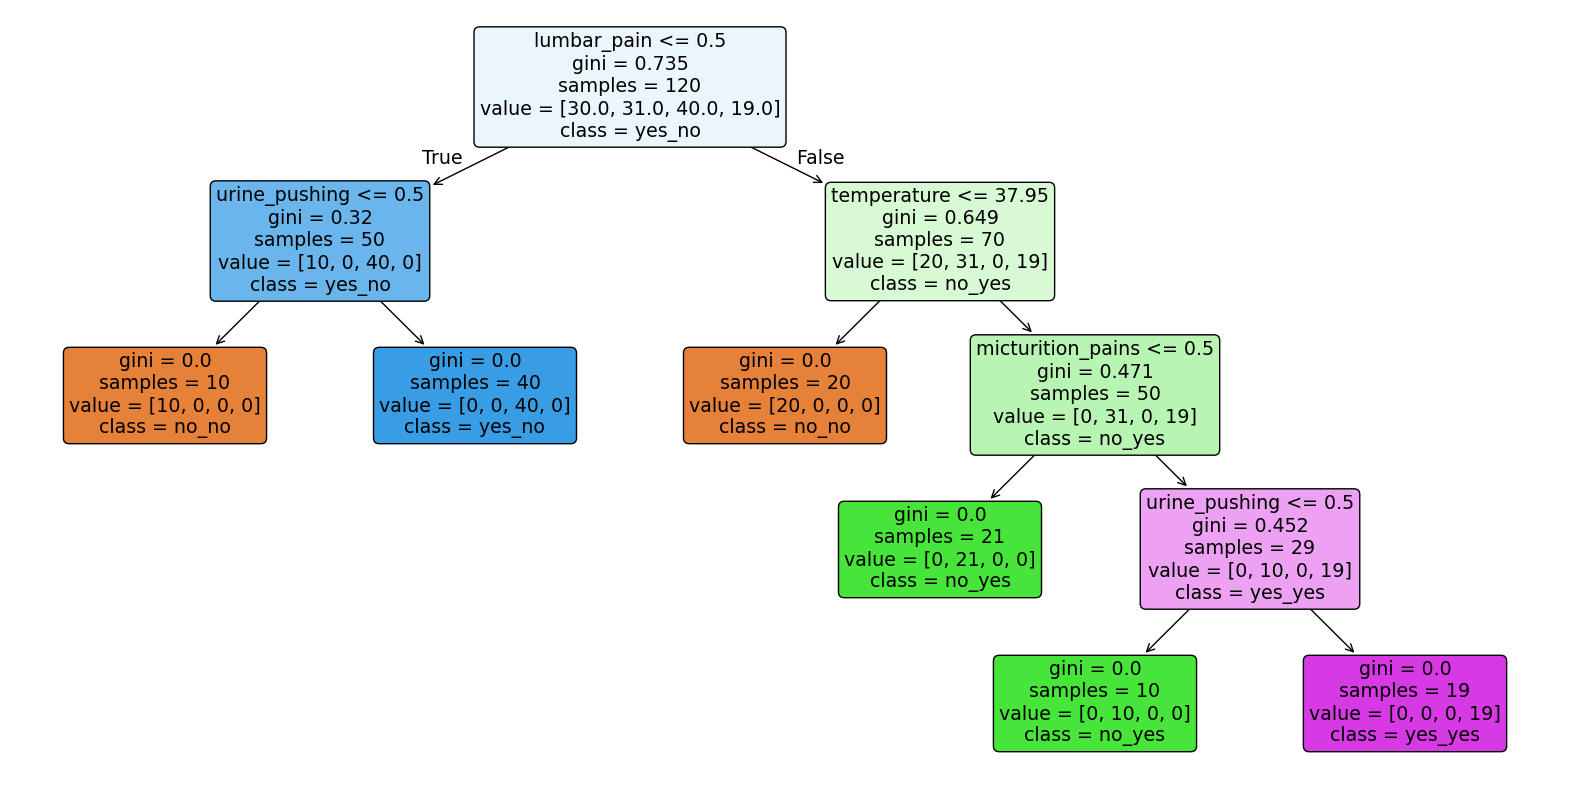

In [9]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.show()

## 1(c) Convert the Decision Tree to IF-THEN Rules

In [10]:
from sklearn.tree import export_text

rules = export_text(
    tree_model,
    feature_names=list(X.columns)
)

print(rules)

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: no_no
|   |--- urine_pushing >  0.50
|   |   |--- class: yes_no
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: no_no
|   |--- temperature >  37.95
|   |   |--- micturition_pains <= 0.50
|   |   |   |--- class: no_yes
|   |   |--- micturition_pains >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: no_yes
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: yes_yes



**Rule 1**

IF `lumbar_pain = no` AND `urine_pushing = no`  
THEN diagnosis = `no_no`.

**Rule 2**

IF `lumbar_pain = no` AND `urine_pushing = yes`  
THEN diagnosis = `yes_no`.

**Rule 3**

IF `lumbar_pain = yes` AND `temperature ≤ 37.95`  
THEN diagnosis = `no_no`.

**Rule 4**

IF `lumbar_pain = yes` AND `temperature > 37.95` AND `micturition_pains = no`  
THEN diagnosis = `no_yes`.

**Rule 5**

IF `lumbar_pain = yes` AND `temperature > 37.95` AND `micturition_pains = yes` AND `urine_pushing = no`  
THEN diagnosis = `no_yes`.

**Rule 6**

IF `lumbar_pain = yes` AND `temperature > 37.95` AND `micturition_pains = yes` AND `urine_pushing = yes`  
THEN diagnosis = `yes_yes`.

## 1(d) Cost-Complexity Pruning

In [11]:
path = tree_model.cost_complexity_pruning_path(X, y)

ccp_alphas = path.ccp_alphas

ccp_alphas

array([0.        , 0.09816667, 0.13333333, 0.182     , 0.22291667])

### Select ccp_alpha Using Cross-Validation

In [12]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=552
)

mean_scores = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        random_state=552,
        ccp_alpha=alpha
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    mean_scores.append(scores.mean())

results = pd.DataFrame({
    "ccp_alpha": ccp_alphas,
    "Mean CV Accuracy": mean_scores
})

results

,ccp_alpha,Mean CV Accuracy
0,0.000000,0.991667
1,0.098167,0.858333
2,0.133333,0.766667
3,0.182000,0.675000
4,0.222917,0.483333


### Compare the Original and Pruned Trees

In [13]:
pruned_tree = DecisionTreeClassifier(
    random_state=552,
    ccp_alpha=0.09816667
)

pruned_tree.fit(X, y)

print("Original tree depth:", tree_model.get_depth())
print("Original number of leaves:", tree_model.get_n_leaves())

print("Pruned tree depth:", pruned_tree.get_depth())
print("Pruned number of leaves:", pruned_tree.get_n_leaves())

Original tree depth: 4
Original number of leaves: 6
Pruned tree depth: 2
Pruned number of leaves: 4


### Plot the Pruned Decision Tree

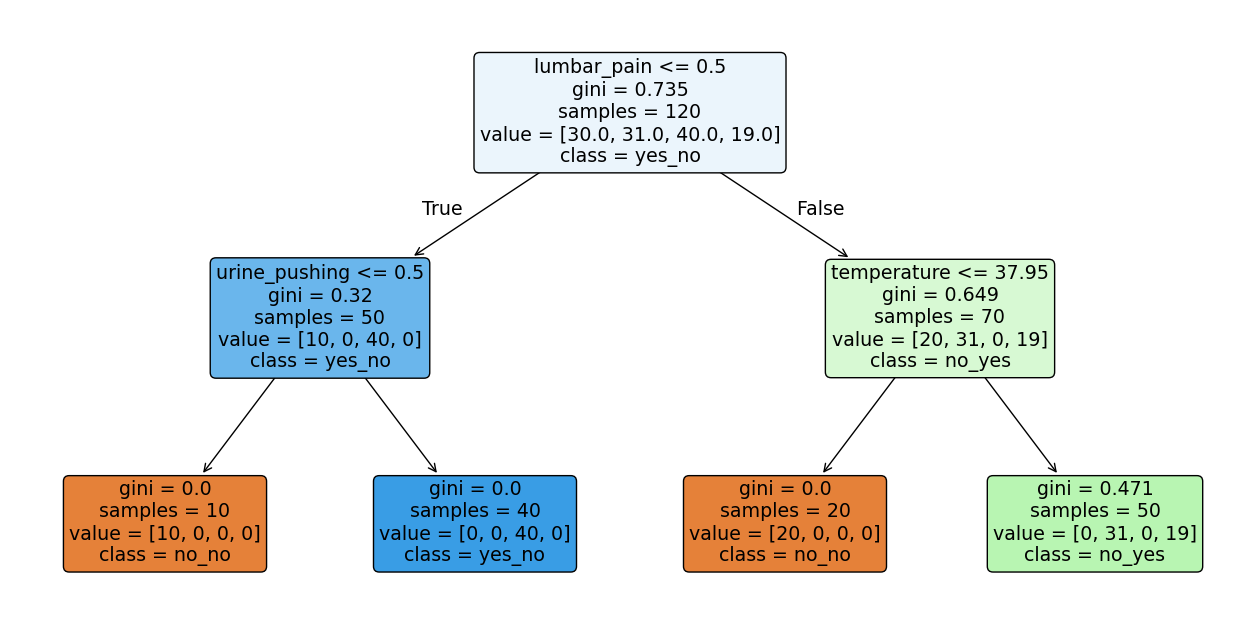

In [14]:
plt.figure(figsize=(16, 8))

plot_tree(
    pruned_tree,
    feature_names=X.columns,
    class_names=pruned_tree.classes_,
    filled=True,
    rounded=True
)

plt.show()

### IF-THEN Rules for the Pruned Tree

In [15]:
pruned_rules = export_text(
    pruned_tree,
    feature_names=list(X.columns)
)

print(pruned_rules)

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: no_no
|   |--- urine_pushing >  0.50
|   |   |--- class: yes_no
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: no_no
|   |--- temperature >  37.95
|   |   |--- class: no_yes



**Rule 1**

IF `lumbar_pain = no` AND `urine_pushing = no`  
THEN diagnosis = `no_no`.

**Rule 2**

IF `lumbar_pain = no` AND `urine_pushing = yes`  
THEN diagnosis = `yes_no`.

**Rule 3**

IF `lumbar_pain = yes` AND `temperature ≤ 37.95`  
THEN diagnosis = `no_no`.

**Rule 4**

IF `lumbar_pain = yes` AND `temperature > 37.95`  
THEN diagnosis = `no_yes`.

### Conclusion

Cross-validation gives the highest accuracy when `ccp_alpha = 0`, which corresponds to the original unpruned tree. Since this part specifically asks for a pruned tree with improved interpretability, I selected the nonzero pruning parameter with the highest cross-validation accuracy, `ccp_alpha = 0.09816667`. This reduces the tree depth from 4 to 2 and the number of leaves from 6 to 4. The pruned tree is substantially simpler and easier to interpret, although its mean cross-validation accuracy decreases to approximately 0.8583.

## 2(a) Load the Communities and Crime Dataset

In [16]:
import pandas as pd

communities = pd.read_csv(
    "communities.data",
    header=None,
    na_values="?"
)

communities.shape

(1994, 128)

### Split the Data into Training and Test Sets

In [17]:
train_data = communities.iloc[:1495].copy()
test_data = communities.iloc[1495:].copy()

print("Training set shape:", train_data.shape)
print("Test set shape:", test_data.shape)

Training set shape: (1495, 128)
Test set shape: (499, 128)


## 2(b) Data Cleaning and Missing Value Imputation

In [18]:
attribute_names = []

with open("communities.names", "r", encoding="latin1") as f:
    for line in f:
        line = line.strip()

        if line.startswith("@attribute"):
            attribute_names.append(line.split()[1])

print("Number of attributes:", len(attribute_names))

Number of attributes: 128


### Assign Column Names

In [19]:
communities.columns = attribute_names

communities.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### Remove Nonpredictive Features

In [20]:
nonpredictive = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

data = communities.drop(columns=nonpredictive)

print("Shape after removing nonpredictive features:", data.shape)

Shape after removing nonpredictive features: (1994, 123)


### Separate Predictors and Response

In [21]:
train_data = data.iloc[:1495].copy()
test_data = data.iloc[1495:].copy()

target = "ViolentCrimesPerPop"

X_train = train_data.drop(columns=[target])
y_train = train_data[target]

X_test = test_data.drop(columns=[target])
y_test = test_data[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1495, 122)
X_test: (499, 122)
y_train: (1495,)
y_test: (499,)


### Check Missing Values

In [22]:
missing_counts = X_train.isnull().sum()

missing_counts[missing_counts > 0].sort_values(ascending=False)

,0
LemasSwornFT,1256
LemasSwFTPerPop,1256
LemasSwFTFieldOps,1256
LemasTotalReq,1256
LemasSwFTFieldPerPop,1256
LemasTotReqPerPop,1256
PolicReqPerOffic,1256
OfficAssgnDrugUnits,1256
PolicPerPop,1256
RacialMatchCommPol,1256


### Impute Missing Values

In [23]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training set:",
      X_train_imputed.isnull().sum().sum())

print("Missing values in test set:",
      X_test_imputed.isnull().sum().sum())

Missing values in training set: 0
Missing values in test set: 0


## 2(c) Correlation Matrix

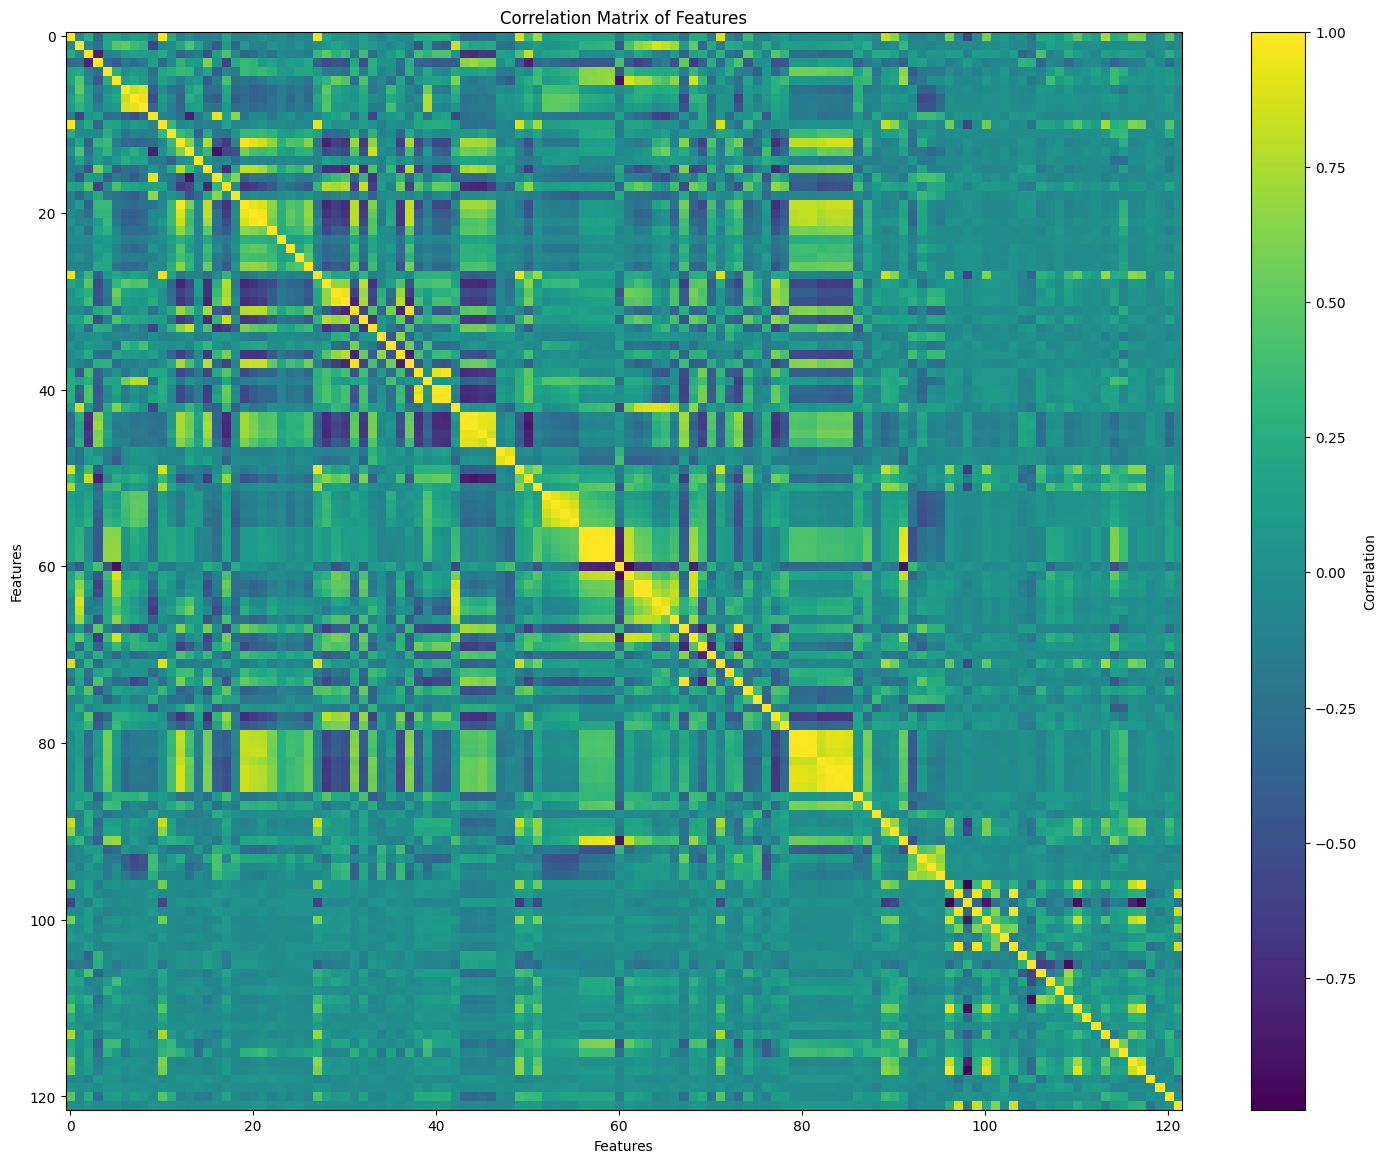

In [24]:
import matplotlib.pyplot as plt

corr_matrix = X_train_imputed.corr()

plt.figure(figsize=(18, 14))
plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix of Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

### Correlation with ViolentCrimesPerPop

In [25]:
train_imputed_full = X_train_imputed.copy()
train_imputed_full["ViolentCrimesPerPop"] = y_train.values

target_corr = (
    train_imputed_full.corr()["ViolentCrimesPerPop"]
    .drop("ViolentCrimesPerPop")
    .abs()
    .sort_values(ascending=False)
)

target_corr.head(10)

,ViolentCrimesPerPop
PctIlleg,0.741866
PctKids2Par,0.741233
PctFam2Par,0.710619
racePctWhite,0.690614
PctTeen2Par,0.668713
PctYoungKids2Par,0.666485
racepctblack,0.644094
pctWInvInc,0.586759
pctWPubAsst,0.581713
FemalePctDiv,0.561824


## 2(d) Coefficient of Variation

In [26]:
feature_mean = X_train_imputed.mean()
feature_std = X_train_imputed.std(ddof=1)

cv = feature_std / feature_mean

cv = cv.replace([np.inf, -np.inf], np.nan)

cv_sorted = cv.sort_values(ascending=False)

cv_sorted

,0
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
...,...
NumKindsDrugsSeiz,0.144382
RacialMatchCommPol,0.134853
PctPolicWhite,0.122813
LemasPctPolicOnPatr,0.115739


### Features with the Highest CV

In [27]:
cv_sorted.head(15)

,0
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
population,2.241105
numbUrban,2.038461
HousVacant,1.968467
LandArea,1.645408


In [28]:
import math

num_features = math.floor(math.sqrt(128))
print(num_features)

11


## 2(e) Features with the Highest CV

In [29]:
import math

num_features = math.floor(math.sqrt(128))

top_features = cv_sorted.head(num_features).index.tolist()

print("Number of selected features:", num_features)
print("Selected features:")
print(top_features)

Number of selected features: 11
Selected features:
['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


### Scatter Plots of Selected Features

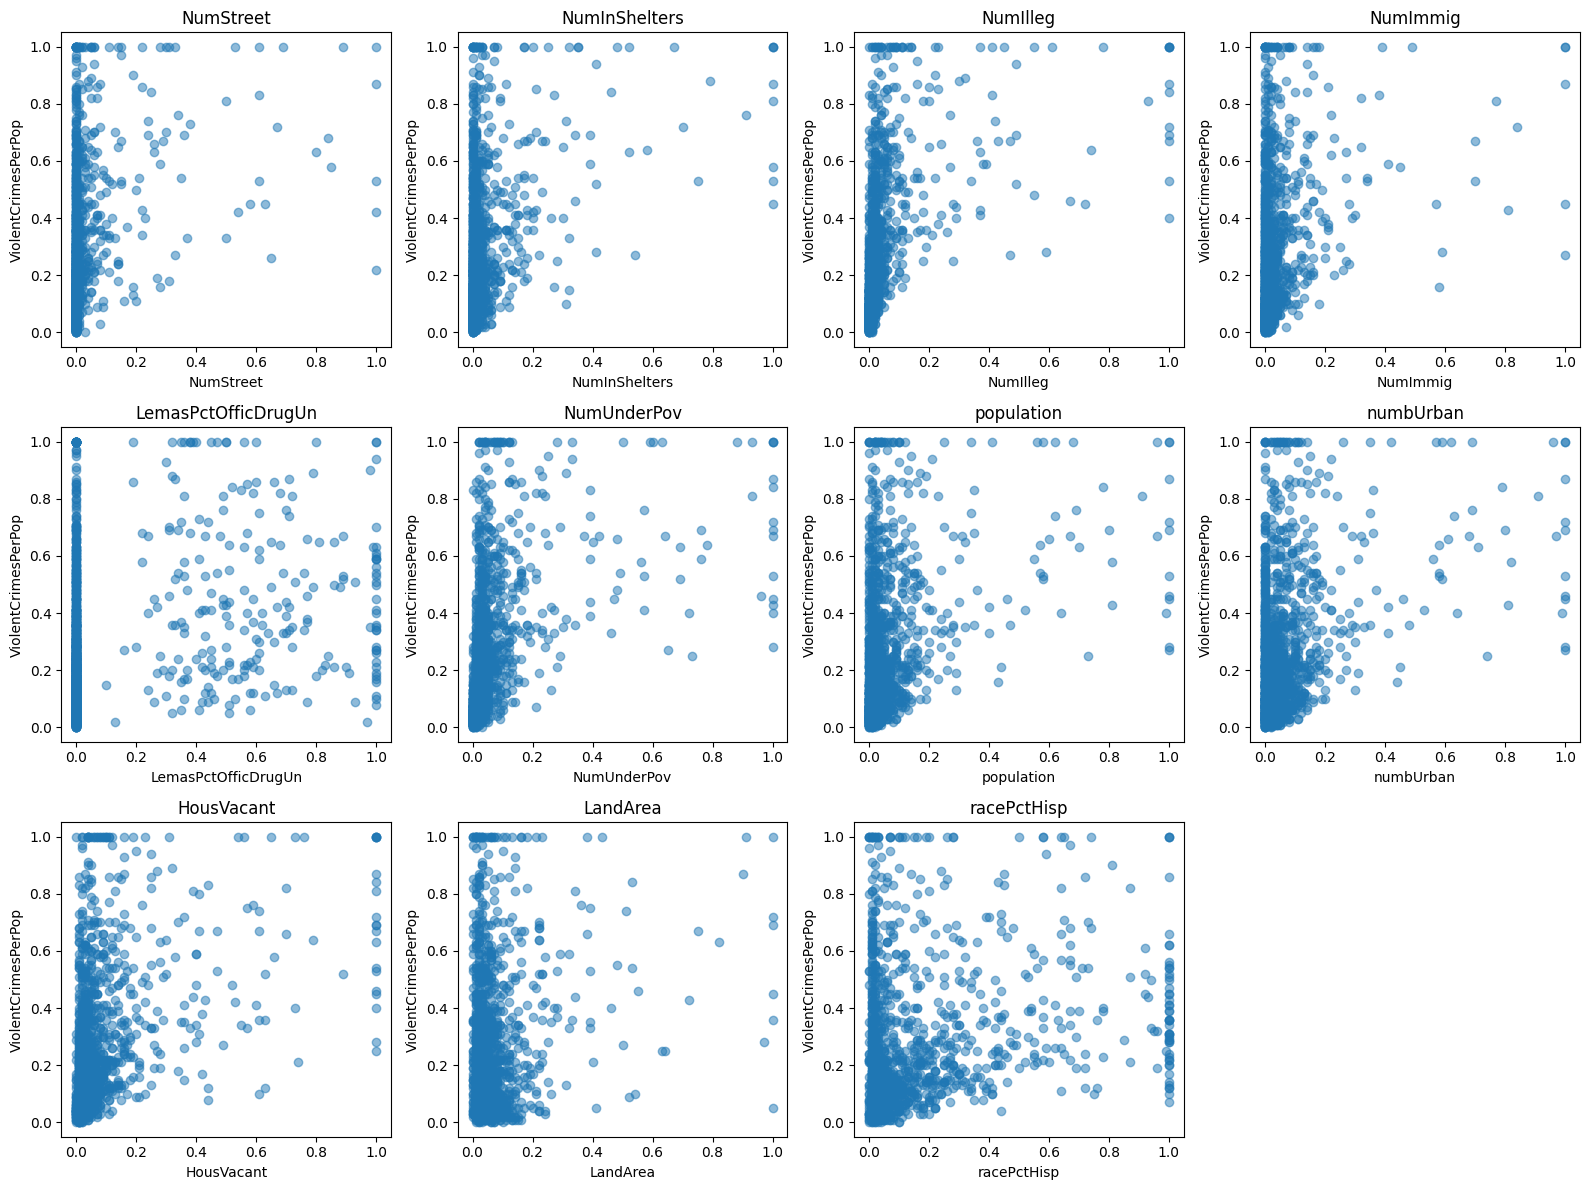

In [30]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_train_imputed[feature],
        y_train,
        alpha=0.5
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

# Remove unused subplot
for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Box Plots of Selected Features

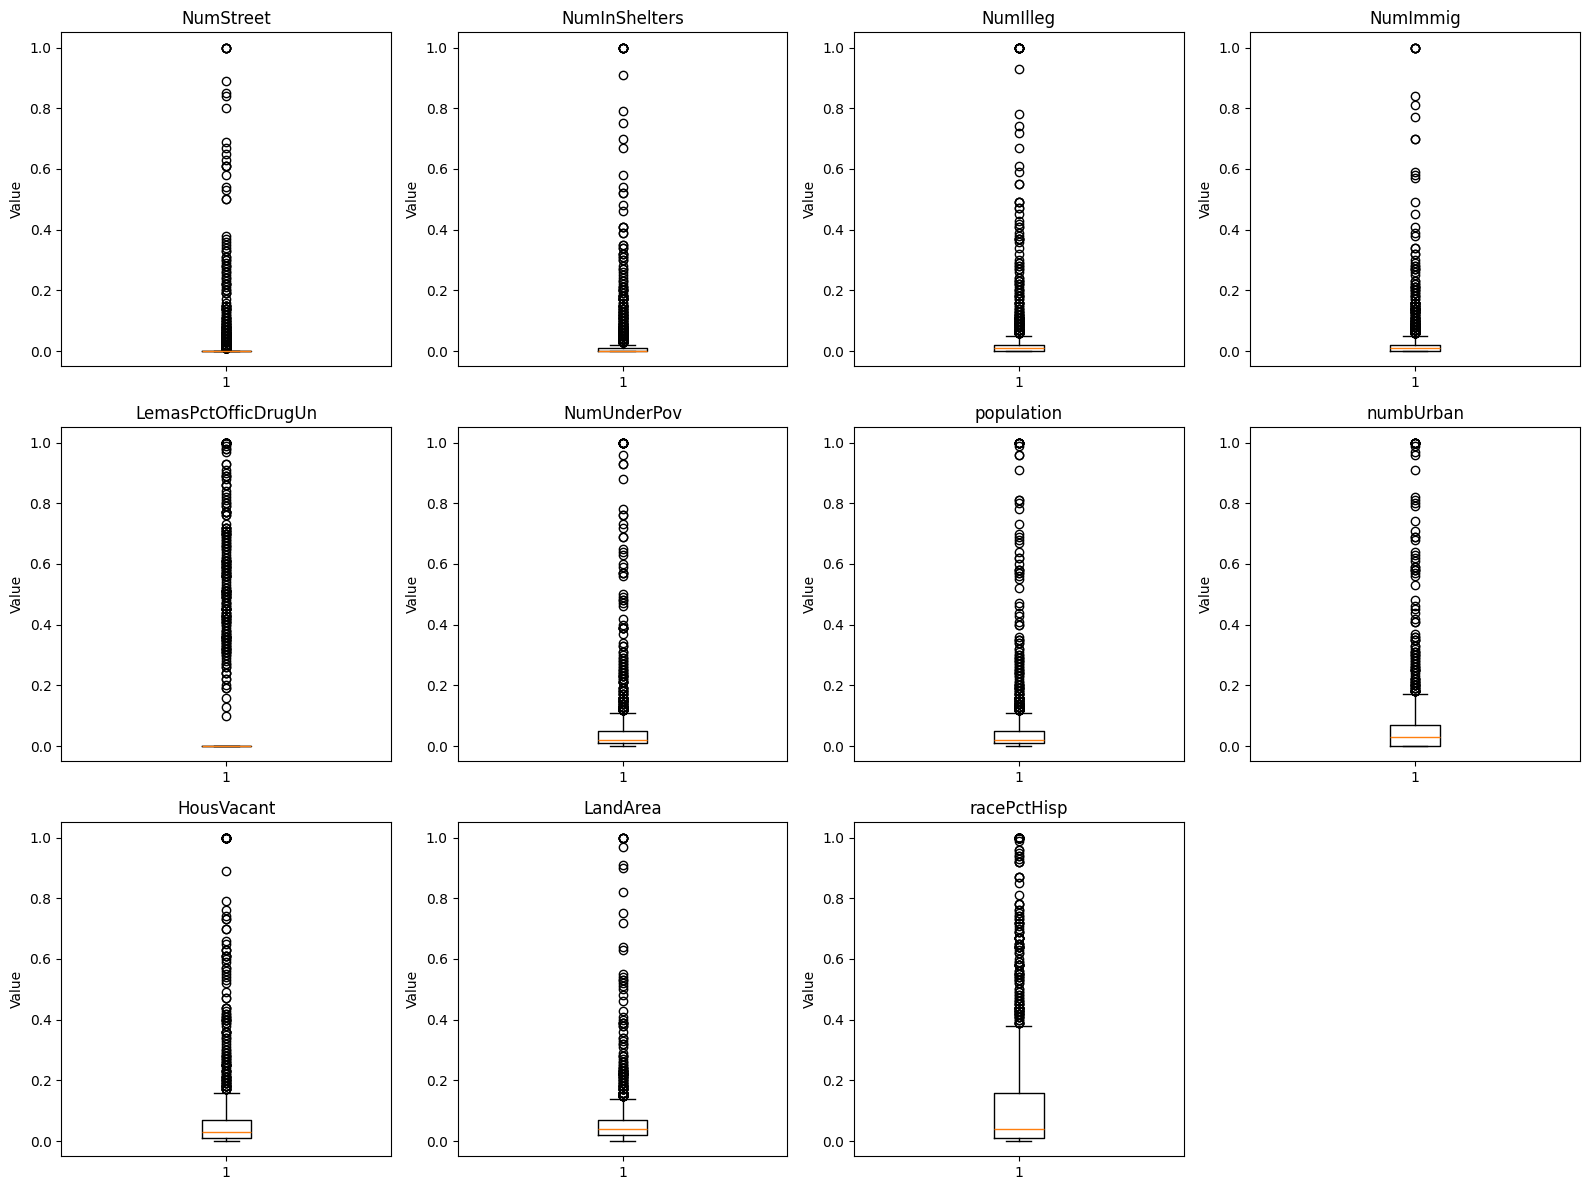

In [31]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].boxplot(X_train_imputed[feature])
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")

for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

No. The scatter plots can show possible relationships between individual features and the response, but they are not enough to determine whether the features are statistically significant. A fitted model and further statistical analysis are needed to evaluate significance.

## 2(f) Least Squares Linear Regression

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

linear_model = LinearRegression()

linear_model.fit(
    X_train_imputed,
    y_train
)

y_pred_linear = linear_model.predict(
    X_test_imputed
)

linear_test_mse = mean_squared_error(
    y_test,
    y_pred_linear
)

print("Test MSE:", linear_test_mse)

Test MSE: 0.01814197113553009


The test error for the least squares linear regression model is reported using mean squared error (MSE).

## 2(g) Ridge Regression with Cross-Validation

In [33]:
from sklearn.linear_model import RidgeCV

alphas = np.logspace(-4, 4, 100)

ridge_model = RidgeCV(
    alphas=alphas,
    cv=5,
    scoring="neg_mean_squared_error"
)

ridge_model.fit(
    X_train_imputed,
    y_train
)

print("Best lambda:", ridge_model.alpha_)

Best lambda: 2.310129700083163


### Ridge Regression Test Error

In [34]:
y_pred_ridge = ridge_model.predict(
    X_test_imputed
)

ridge_test_mse = mean_squared_error(
    y_test,
    y_pred_ridge
)

print("Best lambda:", ridge_model.alpha_)
print("Test MSE:", ridge_test_mse)

Best lambda: 2.310129700083163
Test MSE: 0.01759961379245256


The regularization parameter λ was selected using 5-fold cross-validation. The test error is reported using mean squared error (MSE).

## 2(h) LASSO Regression

In [35]:
from sklearn.linear_model import LassoCV

lasso_model = LassoCV(
    alphas=np.logspace(-4, 0, 100),
    cv=5,
    random_state=552,
    max_iter=10000
)

lasso_model.fit(
    X_train_imputed,
    y_train
)

print("Best lambda:", lasso_model.alpha_)

Best lambda: 0.00012045035402587823


### LASSO Test Error

In [36]:
y_pred_lasso = lasso_model.predict(
    X_test_imputed
)

lasso_test_mse = mean_squared_error(
    y_test,
    y_pred_lasso
)

print("Best lambda:", lasso_model.alpha_)
print("Test MSE:", lasso_test_mse)

Best lambda: 0.00012045035402587823
Test MSE: 0.017747189310170428


### Variables Selected by LASSO

In [37]:
lasso_coefficients = pd.Series(
    lasso_model.coef_,
    index=X_train_imputed.columns
)

selected_variables = lasso_coefficients[
    lasso_coefficients != 0
]

print("Number of selected variables:", len(selected_variables))
selected_variables

Number of selected variables: 76


,0
racepctblack,0.271637
racePctAsian,-0.015033
agePct12t21,0.063171
agePct12t29,-0.257497
pctUrban,0.040412
...,...
PctUsePubTrans,-0.042817
LemasPctPolicOnPatr,0.021360
LemasGangUnitDeploy,0.039908
LemasPctOfficDrugUn,0.002547


### LASSO with Standardized Features

In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [39]:
lasso_scaled = LassoCV(
    alphas=np.logspace(-4, 0, 100),
    cv=5,
    random_state=552,
    max_iter=10000
)

lasso_scaled.fit(
    X_train_scaled,
    y_train
)

y_pred_lasso_scaled = lasso_scaled.predict(
    X_test_scaled
)

lasso_scaled_test_mse = mean_squared_error(
    y_test,
    y_pred_lasso_scaled
)

print("Best lambda:", lasso_scaled.alpha_)
print("Test MSE:", lasso_scaled_test_mse)

Best lambda: 0.000774263682681127
Test MSE: 0.0178020676649981


### Variables Selected by Standardized LASSO

In [40]:
lasso_scaled_coefficients = pd.Series(
    lasso_scaled.coef_,
    index=X_train_imputed.columns
)

selected_variables_scaled = lasso_scaled_coefficients[
    lasso_scaled_coefficients != 0
]

print(
    "Number of selected variables:",
    len(selected_variables_scaled)
)

selected_variables_scaled

Number of selected variables: 73


,0
racepctblack,0.068170
racePctAsian,-0.000807
agePct12t21,0.010167
agePct12t29,-0.037827
pctUrban,0.016543
...,...
PopDens,0.003170
PctUsePubTrans,-0.008712
PolicCars,0.004004
LemasPctPolicOnPatr,0.002080


### Comparison of LASSO Models

In [41]:
comparison = pd.DataFrame({
    "Model": [
        "LASSO",
        "Standardized LASSO"
    ],
    "Test MSE": [
        lasso_test_mse,
        lasso_scaled_test_mse
    ],
    "Number of Selected Variables": [
        len(selected_variables),
        len(selected_variables_scaled)
    ]
})

comparison

,Model,Test MSE,Number of Selected Variables
0,LASSO,0.017747,76
1,Standardized LASSO,0.017802,73


The LASSO model without standardization has a test MSE of approximately 0.01775 and selects 76 variables. The standardized LASSO model has a slightly higher test MSE of approximately 0.01780 and selects 73 variables. Therefore, the unstandardized LASSO performs slightly better in terms of test MSE, while the standardized LASSO produces a slightly sparser model. Overall, the difference in test performance is very small.

## 2(i) Principal Components Regression (PCR)

In [42]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pcr_pipeline = Pipeline([
    ("pca", PCA()),
    ("linear_regression", LinearRegression())
])

param_grid = {
    "pca__n_components": range(1, X_train_imputed.shape[1] + 1)
}

pcr_cv = GridSearchCV(
    pcr_pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

pcr_cv.fit(
    X_train_imputed,
    y_train
)

best_M = pcr_cv.best_params_["pca__n_components"]

print("Best number of principal components:", best_M)

Best number of principal components: 96


### PCR Test Error

In [43]:
y_pred_pcr = pcr_cv.best_estimator_.predict(
    X_test_imputed
)

pcr_test_mse = mean_squared_error(
    y_test,
    y_pred_pcr
)

print("Best M:", best_M)
print("Test MSE:", pcr_test_mse)

Best M: 96
Test MSE: 0.018471778516167835


The number of principal components M was selected using 5-fold cross-validation. The PCR test error is reported using mean squared error (MSE).

## 2(j) XGBoost with L1 Regularization

In [44]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=552
)

alpha_grid = {
    "reg_alpha": np.logspace(-4, 1, 20)
}

xgb_cv = GridSearchCV(
    xgb_model,
    alpha_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

xgb_cv.fit(
    X_train_imputed,
    y_train
)

print("Best alpha:", xgb_cv.best_params_["reg_alpha"])

Best alpha: 0.8858667904100823


### XGBoost Test Error

In [45]:
y_pred_xgb = xgb_cv.best_estimator_.predict(
    X_test_imputed
)

xgb_test_mse = mean_squared_error(
    y_test,
    y_pred_xgb
)

print("Best alpha:", xgb_cv.best_params_["reg_alpha"])
print("Test MSE:", xgb_test_mse)

Best alpha: 0.8858667904100823
Test MSE: 0.016773172648860687


The L1 regularization parameter α was selected using 5-fold cross-validation. The test error is reported using mean squared error (MSE).

## Model Performance Comparison

In [46]:
model_comparison = pd.DataFrame({
    "Model": [
        "Least Squares",
        "Ridge",
        "LASSO",
        "Standardized LASSO",
        "PCR",
        "XGBoost"
    ],
    "Test MSE": [
        linear_test_mse,
        ridge_test_mse,
        lasso_test_mse,
        lasso_scaled_test_mse,
        pcr_test_mse,
        xgb_test_mse
    ]
})

model_comparison = model_comparison.sort_values(
    by="Test MSE"
).reset_index(drop=True)

model_comparison

,Model,Test MSE
0,XGBoost,0.016773
1,Ridge,0.017600
2,LASSO,0.017747
3,Standardized LASSO,0.017802
4,Least Squares,0.018142
5,PCR,0.018472


In [47]:
best_model = model_comparison.iloc[0]

print("Best model:", best_model["Model"])
print("Lowest Test MSE:", best_model["Test MSE"])

Best model: XGBoost
Lowest Test MSE: 0.016773172648860687


The models are compared using test MSE. A lower MSE indicates better test performance. The model with the lowest test MSE provides the best predictive performance on the test set.

Among the models considered, XGBoost achieved the lowest test mean squared error (MSE) of approximately 0.01677. Therefore, XGBoost provided the best predictive performance on the test set.